## Assignment 02: Fitting and Alignment

Index Number - 230052P

GitHub repository - https://github.com/ThisuraSamuditha/EN3160-Assignment-02

## Question 1


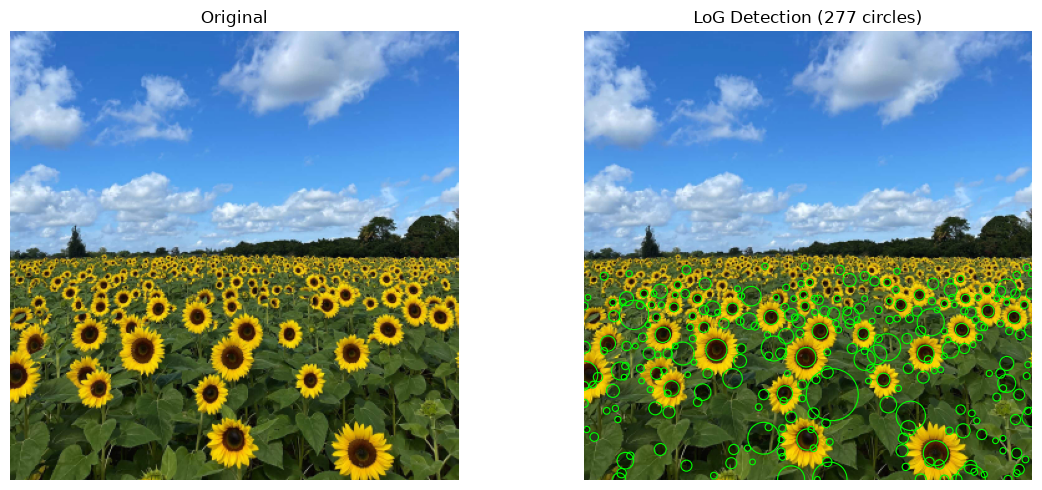

Sigma range: 1.5 - 16.0 pixels
Total circles: 277
Rank   X    Y    Radius   Sigma
   1  199  291    20.85   14.75
   2  197  359    13.87    9.80
   3  144  326    12.78    9.04
   4  310  359    11.78    8.33
   5  262  308    11.78    8.33
   6   40  227    11.78    8.33
   7    0  275    10.85    7.67
   8  166  359    10.85    7.67
   9  278  233    10.85    7.67
  10  243  253    10.85    7.67


In [ ]:

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.ndimage import gaussian_laplace, maximum_filter

im = cv.imread("a2images/the_berry_farms_sunflower_field.jpeg",
               cv.IMREAD_REDUCED_COLOR_4)
if im is None:
    raise FileNotFoundError("Sunflower image not found")

rgb = cv.cvtColor(im, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY) / 255.0
h, w = gray.shape
hsv = cv.cvtColor(im, cv.COLOR_BGR2HSV)
yellow = cv.inRange(hsv, (15, 70, 65), (40, 255, 255)) > 0

# Scale-normalized LoG and 3D extrema
sigmas = np.geomspace(1.5, 16, 30)
S = np.stack([s**2 * gaussian_laplace(gray, s) for s in sigmas])
peaks = (S == maximum_filter(S, size=(3, 7, 7))) & (S > 0.012)
peaks[[0, -1]] = False

# Check dark centers surrounded by yellow petals
def valid(x, y, r):
    if y < 0.52 * h:
        return False
    R = int(np.ceil(max(4, 2*r)))
    x1, x2 = max(0, x-R), min(w, x+R+1)
    y1, y2 = max(0, y-R), min(h, y+R+1)
    yy, xx = np.ogrid[y1:y2, x1:x2]
    d = np.hypot(xx-x, yy-y)
    center = d <= max(1.5, 0.6*r)
    ring = (d >= 0.7*r) & (d <= 2*r)
    g, m = gray[y1:y2, x1:x2], yellow[y1:y2, x1:x2]
    return (m[ring].mean() >= 0.12 and
            g[ring].mean() - g[center].mean() >= 0.06)

# Detect and suppress overlapping circles
candidates = []
for k, y, x in zip(*np.where(peaks)):
    s = sigmas[k]
    r = np.sqrt(2)*s
    if valid(x, y, r):
        candidates.append((x, y, r, s, S[k, y, x]))

candidates.sort(key=lambda b: b[4], reverse=True)
blobs = []
for b in candidates:
    if all(np.hypot(b[0]-p[0], b[1]-p[1]) >=
           0.45*(b[2]+p[2]) for p in blobs):
        blobs.append(b)

# Display one comparison
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(rgb)
ax[0].set_title("Original")
ax[1].imshow(rgb)
for x, y, r, s, v in blobs:
    ax[1].add_patch(Circle((x, y), r, fill=False,
                           edgecolor="lime", lw=0.8))
ax[1].set_title(f"LoG Detection ({len(blobs)} circles)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

# Report largest circles
print(f"Sigma range: {sigmas[0]:.1f} - {sigmas[-1]:.1f} pixels")
print(f"Total circles: {len(blobs)}")
print("Rank   X    Y    Radius   Sigma")
for i, (x, y, r, s, _) in enumerate(
        sorted(blobs, key=lambda b: b[2], reverse=True)[:10], 1):
    print(f"{i:>4} {x:>4} {y:>4} {r:>8.2f} {s:>7.2f}")


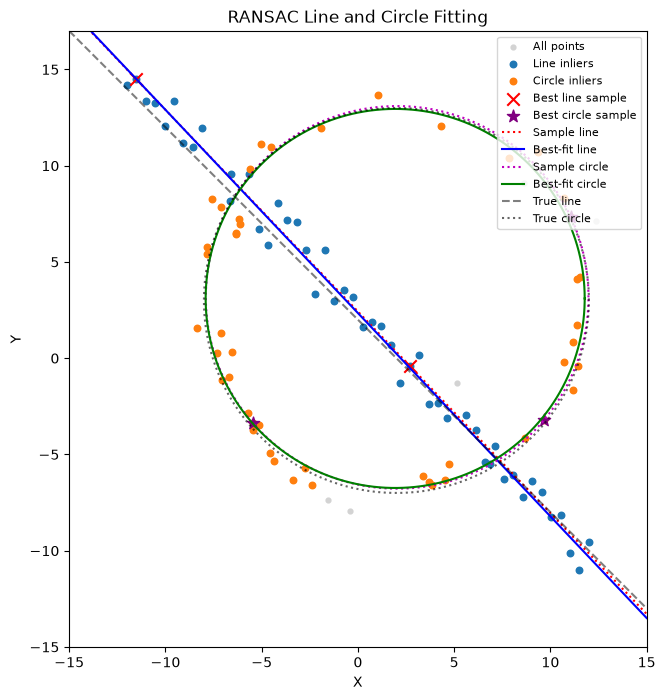

Line inliers: 48
Circle inliers: 47
Line: 0.726x + 0.688y = 1.612
Circle: center=(1.935, 3.104), radius=9.845


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

# Generate noisy line and circle points (Listing 1)
np.random.seed(0)
N, r, cx, cy = 100, 10, 2, 3
t = np.random.uniform(0, 2*np.pi, N//2)
noise = (r/16) * np.random.randn(N//2)
X_circ = np.column_stack((cx+(r+noise)*np.cos(t),
                          cy+(r+noise)*np.sin(t)))
x = np.linspace(-12, 12, N//2)
X_line = np.column_stack((x, -x+2+np.random.randn(N//2)))
X = np.vstack((X_circ, X_line))

rng = np.random.default_rng(0)

# Line model: ax + by = d, with a² + b² = 1
def fit_line(P):
    _, _, V = np.linalg.svd(P - P.mean(axis=0))
    n = V[-1]
    return n, n @ P.mean(axis=0)

def line_error(P, model):
    n, d = model
    return np.abs(P @ n - d)

# Circle model from three points
def fit_circle3(P):
    A = 2 * (P[1:] - P[0])
    b = np.sum(P[1:]**2 - P[0]**2, axis=1)
    if abs(np.linalg.det(A)) < 1e-8:
        return None
    c = np.linalg.solve(A, b)
    return (*c, np.linalg.norm(P[0]-c))

def circle_error(P, model):
    cx, cy, r = model
    return np.abs(np.linalg.norm(P-[cx, cy], axis=1)-r)

# RANSAC: choose model with largest consensus
def ransac(P, sample_size, fit, error, threshold,
           min_inliers, iterations=3000):
    best_count, best_model, best_mask, best_sample = 0, None, None, None

    for _ in range(iterations):
        idx = rng.choice(len(P), sample_size, replace=False)
        sample = P[idx]
        model = fit(sample)
        if model is None:
            continue

        mask = error(P, model) < threshold
        count = mask.sum()

        if count > best_count:
            best_count = count
            best_model, best_mask, best_sample = model, mask, sample.copy()

    if best_count < min_inliers:
        raise RuntimeError("Insufficient RANSAC consensus")

    return best_model, best_mask, best_sample

# (a) Estimate line using custom RANSAC
line_sample_model, line_mask, line_sample = ransac(
    X, 2, fit_line, line_error, threshold=1.0, min_inliers=35
)
line_model = fit_line(X[line_mask])

# (b) Remove line consensus and estimate circle
remaining = X[~line_mask]
circle_sample_model, circle_mask, circle_sample = ransac(
    remaining, 3, fit_circle3, circle_error,
    threshold=1.0, min_inliers=25
)

# Refine circle using nonlinear least squares
initial = circle_sample_model
result = least_squares(
    lambda p: np.linalg.norm(remaining[circle_mask]-p[:2], axis=1)-p[2],
    initial
)
circle_model = result.x

# (c) Plot all required results
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(*X.T, s=12, c="lightgray", label="All points")
ax.scatter(*X[line_mask].T, s=22, c="tab:blue", label="Line inliers")
ax.scatter(*remaining[circle_mask].T, s=22,
           c="tab:orange", label="Circle inliers")
ax.scatter(*line_sample.T, s=80, marker="x",
           c="red", label="Best line sample")
ax.scatter(*circle_sample.T, s=85, marker="*",
           c="purple", label="Best circle sample")

xx = np.linspace(-15, 15, 300)

def draw_line(model, style, label):
    n, d = model
    if abs(n[1]) > 1e-8:
        ax.plot(xx, (d-n[0]*xx)/n[1], style, label=label)

draw_line(line_sample_model, "r:", "Sample line")
draw_line(line_model, "b-", "Best-fit line")

theta = np.linspace(0, 2*np.pi, 400)

def draw_circle(model, style, label):
    a, b, radius = model
    ax.plot(a+radius*np.cos(theta),
            b+radius*np.sin(theta), style, label=label)

draw_circle(circle_sample_model, "m:", "Sample circle")
draw_circle(circle_model, "g-", "Best-fit circle")

# Ground truth models
ax.plot(xx, -xx+2, "k--", alpha=0.5, label="True line")
ax.plot(cx+r*np.cos(theta), cy+r*np.sin(theta),
        "k:", alpha=0.6, label="True circle")

ax.set(xlim=(-15, 15), ylim=(-15, 17),
       xlabel="X", ylabel="Y", title="RANSAC Line and Circle Fitting")
ax.set_aspect("equal")
ax.legend(fontsize=8, loc="upper right")
plt.show()

print(f"Line inliers: {line_mask.sum()}")
print(f"Circle inliers: {circle_mask.sum()}")
print(f"Line: {line_model[0][0]:.3f}x + "
      f"{line_model[0][1]:.3f}y = {line_model[1]:.3f}")
print(f"Circle: center=({circle_model[0]:.3f}, "
      f"{circle_model[1]:.3f}), radius={circle_model[2]:.3f}")


(d)
If the circle is fitted first, some points belonging to the line may be incorrectly identified as circle inliers, especially near the intersections. This can affect the accuracy of the fitted circle and the line fitted afterward. However, RANSAC can still produce good results depending on the inlier threshold and the selected samples.

## Question 3

In [56]:

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Image pairs and destination corners (TL, TR, BR, BL)
pairs = [
    {
        "background": "a2images/Q3_1.1.jpg",
        "foreground": "a2images/Q3_1.2.jpg",
        "reference_size": (489, 350),
        "corners": [
    [86, 145],   # Top-left
    [186, 164],  # Top-right
    [186, 240],  # Bottom-right
    [86, 235]    # Bottom-left
]
    },
    {
        "background": "a2images/Q3_2.1.jpg",
        "foreground": "a2images/Q3_2.2.png",
        "reference_size": (2048, 1382),
        "corners": [
        [767, 280],   # Top-left
        [1062, 240],  # Top-right
        [1060, 427],  # Bottom-right
        [767, 445]    # Bottom-left
    ]
    }
]

def apply_homography(pair):
    bg = cv.imread(pair["background"])
    fg = cv.imread(pair["foreground"], cv.IMREAD_UNCHANGED)

    if bg is None or fg is None:
        raise FileNotFoundError("Check image paths.")

    bh, bw = bg.shape[:2]
    ref_w, ref_h = pair["reference_size"]

    # Handle PNG transparency
    if fg.ndim == 3 and fg.shape[2] == 4:
        alpha = fg[:, :, 3].astype(np.float32) / 255
        mask = (alpha > 0).astype(np.uint8)
        bounds = cv.findNonZero(mask)

        if bounds is None:
            raise ValueError("Overlay image is fully transparent.")

        x, y, w, h = cv.boundingRect(bounds)
        alpha = alpha[y:y+h, x:x+w]
        fg = fg[y:y+h, x:x+w, :3]
    else:
        alpha = np.ones(fg.shape[:2], dtype=np.float32)

    h, w = fg.shape[:2]

    # Source and destination points
    src = np.float32([
        [0, 0], [w-1, 0],
        [w-1, h-1], [0, h-1]
    ])

    dst = np.float32(pair["corners"])
    dst *= [bw/ref_w, bh/ref_h]

    # Calculate homography
    H = cv.getPerspectiveTransform(src, dst)

    # Warp overlay and alpha mask
    warped = cv.warpPerspective(fg, H, (bw, bh))
    warped_alpha = cv.warpPerspective(alpha, H, (bw, bh))

    # Alpha blending
    a = np.clip(warped_alpha * 0.9, 0, 1)[..., None]

    result = (
        bg.astype(np.float32) * (1-a) +
        warped.astype(np.float32) * a
    ).astype(np.uint8)

    # Single comparison
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    ax[0].imshow(cv.cvtColor(bg, cv.COLOR_BGR2RGB))
    ax[0].set_title("Original Image")

    ax[1].imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
    ax[1].set_title("Homography Overlay")

    for a in ax:
        a.axis("off")

    plt.tight_layout()
    plt.show()

for pair in pairs:
    apply_homography(pair)
